<center>
    <img src="https://upload.wikimedia.org/wikipedia/commons/6/6f/Dauphine_logo_2019_-_Bleu.png" style="width: 600px;"/> 
</center>  

<div align="center"><span style="font-family:Arial Black;font-size:33px;color:darkblue"> Master Economie Finance </span></div>


<div align="center"><span style="font-family:Arial Black;font-size:27px;color:darkblue">Application Lab – Gradient Descent</span></div>

<div align="center"><span style="font-family:Arial Black;font-size:20px;color:darkblue">Logistic Regression Model
</span></div>

# Gradient Descent

Gradient descent is a numerical minimization algorithm for a function.

It is used when there is no analytical solution available (or when it is not easily computable).

 **Parameters:**
 - Let $ f : x \longmapsto f(x) $ be a function to minimize.
 - Let $ \beta_0 \in \mathbb{R} $ be a starting point for the algorithm (its initialization at $ t = 0 $).
 - Let $ \epsilon > 0 $ (small) be a tolerance threshold for the optimization error (example: $ \epsilon = 10^{-8} $ ).
 - Let $ c \in \mathbb{R}^{+*} $ be a step size and $ t $ the number of iterations already performed: $ \gamma_t = \frac{c}{\sqrt t} $ .
 - $ K_{max} \in \mathbb{N} $ is an integer defining the maximum number of iterations of the algorithm.

The algorithm is as follows:

For $ t = 0 $ up to $ K_{max} $:
 - 1: Compute the gradient of the function $ f $, $ \nabla(f) : \beta_t \longmapsto \nabla f(\beta_t) $
 - 2: If $ ||\nabla f(\beta_t)|| < \epsilon $:
   - stop the algorithm and $ \beta_t $ is taken as the minimum of the function.
 - Otherwise:
   - Set $ \beta_{t+1} = \beta_t - \gamma_t \nabla f(\beta_t) $
 - 3: Re-iterate starting from step 1.

Here we will work in $ \mathbb{R} $, so we have a one-dimensional problem, we choose:
$$ ||.|| : x \longmapsto |x| $$

---
# Log-Likelihood Maximization Exercise using Gradient Descent

## Logistic Regression Model

The logistic regression model is a regression model widely used for handling binary variables in statistics.

In a Machine Learning approach, this is referred to as a classification model.

**Objective :** Find the parameter $ \beta ^* $ that was used to simulate the $ Y_i $

***Logistic Model***:

$$ Y_i^* = \beta x_i + \epsilon _i  , \epsilon _i \sim \mathcal{L}$$
$$ Y_i = \left\{
    \begin{array}{ll}
        1 & \mbox{if }  Y_i^* > 0 \\
        0 & \mbox{otherwise.}
    \end{array}
\right. $$ 

The noise $ \epsilon_i $ follows a continuous logistic distribution $\mathcal{L}$ on $\mathbb{R}$ with density (symmetric with respect to 0) with respect to the Lebesgue measure:

$$ \forall x \in \mathbb{R} , f(x)= \frac{e^{-x}}{(1 + e^{-x})^2} $$

For $ i = 1, ..., n $ we observe the dependent variable $ Y $ and the explanatory variable $ (x_i)_{i=1}^n $, which we assume are drawn $(iid)$ from a standard normal distribution:

$$ \forall i, x_i \sim \mathcal{N}(0,1) $$

**NB: The observations \$ Y_i \$ are independent but not identically distributed.**

Likelihood of the observations:
$$ L(y_1,y_2,...,y_n,\beta) = \prod_{i=1}^{n} \mathbb{P}({Y_i = y_i})$$

Log-likelihood of the observations:

$$ l(y_1,y_2,...,y_n,\beta) = log(\prod_{i=1}^{n} \mathbb{P}({Y_i = y_i})) = \sum_{i=1}^{n} log(\mathbb{P}({Y_i = y_i})) $$

We will now denote $ l(\beta) $ instead of $ l(y_1, y_2, ..., y_n, \beta) $ since we treat the log-likelihood of the observations as a function of the parameter $ \beta $ and not as a function of the data in the maximum likelihood problem.

Log-likelihood to **maximize**:
$$ \forall \beta \in \mathbb{R} , l(\beta) = - \sum_{i=1}^{n} log(1+e^{-\beta x_i}) - \beta \sum_{i:Y_i = 0}x_i $$

Negative log-likelihood to **maximize**:

$$ \forall \beta \in \mathbb{R} , -l(\beta) = \beta \sum_{i:Y_i = 0}x_i + \sum_{i=1}^{n} log(1+e^{-\beta x_i}) $$

Gradient of the negative log-likelihood:

$$ \forall \beta \in \mathbb{R} , (-l(\beta))' = \sum_{i:Y_i = 0}x_i - \sum_{i=1}^{n} \frac{x_i e^{-\beta x_i}}{1 + e^{-\beta x_i}}$$

---
## Imports

In [1]:
from math import *
from random import *
import matplotlib.pyplot as plt 
import numpy as np
from tqdm import tqdm
from scipy.optimize import minimize
from typing import Callable
np.random.seed(seed=1)

---
## Simulation

Set \$ n \$ as the number of random draws of \$ Y^\* \$ (start with 100 draws).

In [2]:
n = 1000 # Sample size

Simulation of a standard normal distribution for the \$n\$-sample \$(x\_1, ... , x\_n)\$ in a variable named `x`.

In [3]:
x = np.random.normal(0,1,n)

Simulation of a logistic distribution for the \$n\$-sample \$(\epsilon\_1, ... , \epsilon\_n)\$ in a variable named `epsilon`.


In [4]:
epsilon = np.random.logistic(0,1,n)

Initialization of an arbitrary \$ \beta^\* \$ in a variable named `beta_star` (arbitrary).

In [5]:
beta_star = 1

Simulation of the variable \$ Y^\* \$ using \$ \epsilon \$ and \$ x \$ in a variable named `Y_star`.


In [6]:
Y_star = beta_star * x + epsilon

In [7]:
Y_star

array([ 1.16435974e+00, -6.40234844e-01, -1.60325232e+00,  9.67357964e-01,
        3.89688323e-01, -3.16041240e+00,  2.67737471e+00, -2.20557430e+00,
       -1.69061879e+00,  1.38668724e+00,  2.52968528e+00, -1.69402300e+00,
       -1.45930853e+00,  1.19299372e-01,  1.70200232e+00, -1.81909004e+00,
       -2.79833908e+00,  1.11968202e+00, -1.18303095e-01,  1.75684540e+00,
       -2.17859840e+00,  1.51442659e+00,  6.14822160e-01,  2.18527828e-02,
       -1.02948015e+00, -1.81315593e+00, -2.57421694e+00, -1.76949306e+00,
        7.86960125e-01,  9.98800814e-01,  2.74496842e-02, -5.16987506e+00,
        5.91503011e-02, -8.32482708e-01, -1.87443483e+00, -1.56397900e+00,
       -2.60025562e+00,  1.92468829e+00,  5.69293705e+00,  3.10221948e+00,
       -8.22457968e-01,  3.79346629e-01, -5.60802476e-01,  3.18488243e+00,
       -1.43074380e-02, -2.73231596e-01,  1.49942387e+00, -9.43650098e-02,
        2.68458617e-01,  6.77157200e-02,  7.23613355e-01,  2.79505808e+00,
       -1.57797965e+00, -

---
## Functions

In [8]:
x

array([ 1.62434536e+00, -6.11756414e-01, -5.28171752e-01, -1.07296862e+00,
        8.65407629e-01, -2.30153870e+00,  1.74481176e+00, -7.61206901e-01,
        3.19039096e-01, -2.49370375e-01,  1.46210794e+00, -2.06014071e+00,
       -3.22417204e-01, -3.84054355e-01,  1.13376944e+00, -1.09989127e+00,
       -1.72428208e-01, -8.77858418e-01,  4.22137467e-02,  5.82815214e-01,
       -1.10061918e+00,  1.14472371e+00,  9.01590721e-01,  5.02494339e-01,
        9.00855949e-01, -6.83727859e-01, -1.22890226e-01, -9.35769434e-01,
       -2.67888080e-01,  5.30355467e-01, -6.91660752e-01, -3.96753527e-01,
       -6.87172700e-01, -8.45205641e-01, -6.71246131e-01, -1.26645989e-02,
       -1.11731035e+00,  2.34415698e-01,  1.65980218e+00,  7.42044161e-01,
       -1.91835552e-01, -8.87628964e-01, -7.47158294e-01,  1.69245460e+00,
        5.08077548e-02, -6.36995647e-01,  1.90915485e-01,  2.10025514e+00,
        1.20158952e-01,  6.17203110e-01,  3.00170320e-01, -3.52249846e-01,
       -1.14251820e+00, -

Computation of the negative log-likelihood using a function named `f`.

$$ Y_i^* = \beta x_i + \epsilon _i  , \epsilon _i \sim \mathcal{L}$$
$$ Y_i = \left\{
    \begin{array}{ll}
        1 & \mbox{if }  Y_i^* > 0 \\
        0 & \mbox{otherwise.}
    \end{array}
\right. $$ 

$$
\boxed{
J(\beta)
=
\beta
\sum_{i:y_i=0} x_i
+
\sum_{i=1}^{n}
\log\left(1+e^{-\beta x_i}\right)
}
$$

In [9]:
def f(B : float) -> float :
    f = -np.sum(np.log(1+np.exp(-B*x))) - B*np.sum(x[Y_star<0])
    return -f

Computation of the gradient of the negative log-likelihood in a function named `grad_f`.

$$
\boxed{
J'(\beta)
=
\sum_{i:y_i=0} x_i
-
\sum_{i=1}^{n}
\frac{x_i e^{-\beta x_i}}
{1+e^{-\beta x_i}}
}
$$

In [10]:
def grad_f(B : float) -> float :
    return np.sum(-x*np.exp(-B*x)/(1+np.exp(-B*x))) + np.sum(x[Y_star<0])

Function to perform gradient descent by fixing its parameters:

* \$ \beta\_0 \in \mathbb{R} \$ the starting point for the algorithm (its initialization at \$ t = 0 \$).
* \$ \nabla (f) : \beta\_t \longmapsto \nabla f(\beta\_t) \$ the gradient.
* \$ K\_{max} \in \mathbb{N} \$ an integer defining the maximum number of iterations of the algorithm.
* \$ \epsilon > 0 \$ (small) a tolerance threshold for the optimization error (example: \$ \epsilon = 10^{-8} \$).
* \$ c \in \mathbb{R}^{+\*} \$ the step size used to compute: \$ \gamma\_t = \frac{c}{\sqrt{t}} \$.

*Name the function `GF` and remember to type the inputs and the output.*


$$
\beta_i
=
\beta_{i-1}
-
\frac{c}{\sqrt{i}}
J'(\beta_{i-1})
$$

For $ t = 0 $ up to $ K_{max} $:
 - 1: Compute the gradient of the function $ f $, $ \nabla(f) : \beta_t \longmapsto \nabla f(\beta_t) $
 - 2: If $ ||\nabla f(\beta_t)|| < \epsilon $:
   - stop the algorithm and $ \beta_t $ is taken as the minimum of the function.
 - Otherwise:
   - Set $ \beta_{t+1} = \beta_t - \gamma_t \nabla f(\beta_t) $
 - 3: Re-iterate starting from step 1.

In [11]:
# df is the derivative of the objective function
def GF(B0 : float,df : Callable ,KMAX : int ,eps : float ,c : float) -> float:
    beta = B0
    for i in tqdm(range(1, KMAX+1)):
        if(np.abs(df(beta))>eps):
             beta -= (c/sqrt(i))*df(beta)
        else:
            break
    return beta

---

## Curve of the function to minimize


Plot the log-likelihood by simulating the inputs (with `np.linspace`) and the outputs (using the function `f` already coded above).

Use matplotlib for the graph (`matplotlib.pyplot.plot`).

Add a vertical line at \$ \beta^\* \$ to visually check whether the log-likelihood has a minimum and whether this minimum is indeed at \$ \beta^\* \$.


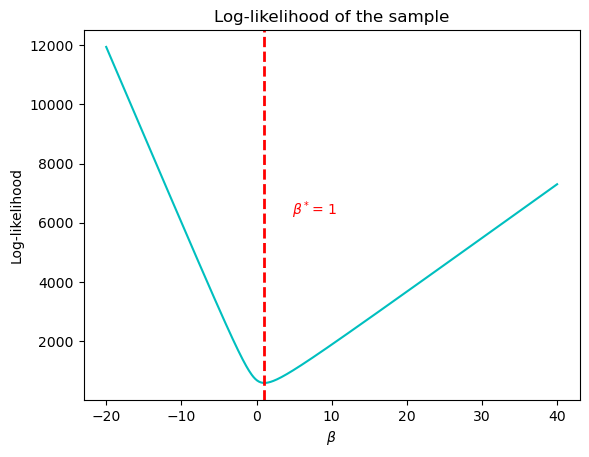

In [216]:
Beta_vector = np.linspace(-20,40, num=500)

vrais = [f(i) for i in Beta_vector]
    
plt.plot(Beta_vector,vrais,
         color='c')
plt.axvline(beta_star, color='r', linestyle='dashed', linewidth=2)
plt.xlabel(r'$\beta$')
plt.ylabel('Log-likelihood')
plt.title('Log-likelihood of the sample')

min_xlim, max_xlim = plt.xlim()
min_ylim, max_ylim = plt.ylim()
plt.text(min_xlim+ 0.42*(max_xlim-min_xlim),min_ylim + 0.5*(max_ylim-min_ylim), r'$\beta^*$'+'= {}'.format(beta_star), color='r')
plt.show()

---

## Search for the optimal \$ \beta \$ with different step sizes


Perform gradient descent for several different step sizes \$ c \$:
\$ \[0.00001, 0.0001, 0.001, 0.01, 0.1, 0.5, 1, 2, 3, 10] \$

Store the values found in a list named `l`.

In [12]:
C = [0.001,0.01,0.1,0.5,1,2,3,10]
l = [GF(B0=0,df=grad_f,KMAX=3*10**4,eps=10**(-8),c=c) for c in C]

  0%|                                                                                               | 0/30000 [00:00<?, ?it/s]C:\Users\mateo\AppData\Local\Temp\ipykernel_14040\532554113.py:2: RuntimeWarning: overflow encountered in exp
  return np.sum(-x*np.exp(-B*x)/(1+np.exp(-B*x))) + np.sum(x[Y_star<0])
C:\Users\mateo\AppData\Local\Temp\ipykernel_14040\532554113.py:2: RuntimeWarning: invalid value encountered in divide
  return np.sum(-x*np.exp(-B*x)/(1+np.exp(-B*x))) + np.sum(x[Y_star<0])
  0%|                                                                                      | 1/30000 [00:00<00:43, 684.23it/s]


In [13]:
l

[np.float64(1.0574459193648935),
 np.float64(1.0574459195076673),
 np.float64(1.0574459194794625),
 np.float64(1.0574459193761192),
 np.float64(269.71781297463616),
 np.float64(412.9822488026298),
 np.float64(619.4733732039447),
 np.float64(2064.911244013149)]

Using a simple loop over the list `l`, display the following sentence for each value of \$ c \$:

* `"With c=... : beta = ..."`


In [20]:
C = [0.001,0.01,0.1,0.5,1,2,3,10]
for i,beta in enumerate(l) :
    print(f'With c={C[i]}, beta = {beta}')

With c=0.001, beta = 1.0574459193648935
With c=0.01, beta = 1.0574459195076673
With c=0.1, beta = 1.0574459194794625
With c=0.5, beta = 1.0574459193761192
With c=1, beta = 269.71781297463616
With c=2, beta = 412.9822488026298
With c=3, beta = 619.4733732039447
With c=10, beta = 2064.911244013149


"What do we observe? What is the contribution of tqdm?"


---

## Verification of our results with a function from the `scipy.optimize` package


Minimize the function `f` (negative log-likelihood) using the `minimize` function from the `scipy` package and compare with the results obtained by gradient descent.


In [21]:
mymin = minimize(f, 0, method='nelder-mead')
print(f'beta optimal : {mymin["x"][0]}')

beta optimal : 1.0574375000000011


Using the `minimize` function from `scipy`, we can check the relevance of our gradient descent algorithm. Looking at the \$\beta\$ values obtained when the algorithm was used with appropriate \$c\$, we can see that the values match up to \$10^{-4}\$.


## Test of log-likelihood function minimization with random starting points


Draw \$1000\$ random \$ \beta\_0 \$ from a uniform distribution \$ U\[-100, 100] \$ and minimize (with `scipy.optimize.minimize`) the function \$ f \$ for all sampled \$ \beta\_0 \$.

Then, create a histogram (`matplotlib.pyplot.hist`) of the distribution of the solutions found for each \$ \beta\_0 \$, and add a vertical line at the mean.

In [22]:
unif_sample_estimation = list()
for Beta_0 in np.random.uniform(-100,100,10000):
    unif_sample_estimation.append(minimize(f, Beta_0, method='nelder-mead')["x"][0])

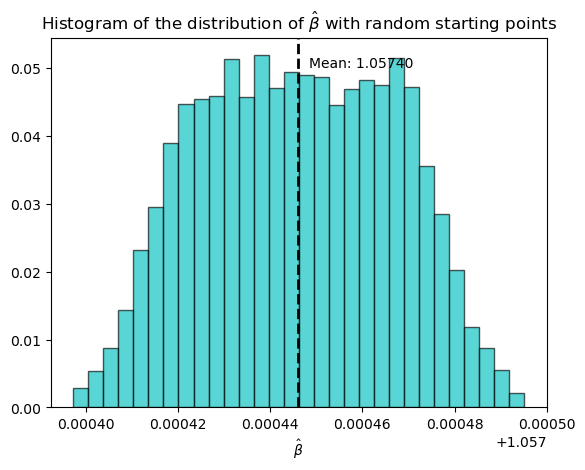

In [230]:
plt.hist(unif_sample_estimation,
         bins=30,
         color='c',
         edgecolor='k',
         alpha=0.65,
         weights=np.ones_like(unif_sample_estimation) / len(unif_sample_estimation))
plt.axvline(np.mean(unif_sample_estimation), color='k', linestyle='dashed', linewidth=2)
plt.xlabel(r'$\hat\beta$')
plt.title('Histogram of the distribution of '+r'$\hat\beta$'+' with random starting points')
min_xlim, max_xlim = plt.xlim()
min_ylim, max_ylim = plt.ylim()
plt.text(min_xlim+ 0.52*(max_xlim-min_xlim),min_ylim + 0.92*(max_ylim-min_ylim), 'Mean: {:.5f}'.format(round(np.mean(unif_sample_estimation),4)))
plt.show()